# WP10 — Gerçek moleküler graf,encoder ve entegrasyon

Kullanıcı tasarımv1'i **graf/encoder/teknik test** uygulaması için onayladı. Kaynak WP04 DrugBank XML SMILES,CID köprüsü ve mevcutQC. **62 envanter;54 atom dalı açık,8 inceleme maskesi kapalı.** Yeni kaynak yok.

Bu notebook gerçek PyG2.8.0 Data ve forward/backward gösterir. Bütün ağırlıklar **eğitilmemiş başlangıç/sentetik kanıt ağırlıklarıdır**;optimizer veya gerçekPT loss yoktur. Moleküler temsil bir yan etki skoru değildir. Outer ilaçlar yalnız etiketsiz query temsil izolasyonu için incelendi;PT skorlaması/performans tablosu yapılmadı.

In [1]:
from pathlib import Path
import sys,json,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display,Image
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
from wp10_molecular_graph import QA,Chem,torch,Batch,load_store,build_graph,parse_smiles,slices
from wp10_molecular_encoder import initialized_model,BondAwareMolecularEncoder,load_context,VARIANTS
torch.set_num_threads(1)
F=ROOT/'reports/figures/WP10/encoder_v1';F.mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20);pd.set_option('display.max_colwidth',90)
store=load_store();env=json.loads((QA/'environment.json').read_text(encoding='utf-8'));audit=json.loads((QA/'technical_audit_complete.json').read_text(encoding='utf-8'))
display(pd.DataFrame([env]));display(pd.DataFrame([audit]).T.rename(columns={0:'gerçek_kontrol'}))
display(store.graphs['DB00601'])

,python,torch,PyG,RDKit,CPU_threads,deterministic_algorithms,device,optimizer_steps
0,3.11.3,2.13.0+cpu,2.8.0,2026.09.1,1,True,CPU,0


,gerçek_kontrol
status,PASS
version,WP10-molecular-encoder-v1
real_PyG_graphs,62
QC_atom_enabled,54
QC_atom_disabled,8
atoms,2061
undirected_bonds,2219
directed_edges,4438
permutation_cases,62
maximum_permutation_error,0.0


Data(x=[24, 44], edge_index=[2, 52], edge_attr=[52, 14], num_nodes=24)

**Yorum:** Gerçek Linezolid PyG Data nesnesi x[24,44],edge_index[2,52],edge_attr[52,14] taşır. Kimlik,ad,hamSMILES,QC ve stereo referansları ayrıregistry'dedir;y/PT alanı Data'da yoktur. `.deps/pyg`2.8.0 gerçek çalışma ortamıdır;kurulum yapılmadı. Özellikler sabit şemadan gelir,testten sözlük/scaler öğrenilmedi.

## 1. Tüm62 graf ve54/8 maskesi

,id,name,cid,atoms,bonds,directed_edges,components,atom_eligible,review_flags,PyG_validate,identity_match,x_dim,edge_dim,y_present,graph_tensor_sha256
0,DB00199,Erythromycin,12560,51,53,106,1,True,NaN,True,True,44,14,False,c1962fab10e20c62531d1760b3af24e9f235fe0de0ff5d6d043c55e6e1f3c0bb
1,DB00207,Azithromycin,447043,52,54,108,1,True,NaN,True,True,44,14,False,6749bc09bdc67a9d44626b2633bd7f1cb4946b5d8288ff426f9caf819d4ca2e0
2,DB00254,Doxycycline,54671203,34,37,74,1,True,NaN,True,True,44,14,False,a5fd17f15b49cde16ff67b852fdfb4d10ac045daf3053d0338afc9fb42d9d8de
3,DB00259,Sulfanilamide,5333,11,11,22,1,True,NaN,True,True,44,14,False,7a3fa1e8fece25d5b8eecf9fe5dbf5a31cd3b52b76916e2611dcce9008df81c0
4,DB00301,Flucloxacillin,21319,31,34,68,1,True,NaN,True,True,44,14,False,2b175dd835a660265553635f800c3a3361a0d3203044e9ca4bf9261b79a2f92d
5,DB00303,Ertapenem,150610,37,40,80,1,True,NaN,True,True,44,14,False,a2e089b392d4ef839834308bc77c60d0a8c047b1b27ab8a4fe4747f9050032dd
6,DB00319,Piperacillin,43672,37,40,80,1,True,NaN,True,True,44,14,False,2d3ea0ebcd3fc5314b2198853edebaf360494eafa20a661b8d6df36b01bc3a03
7,DB00359,Sulfadiazine,5215,17,18,36,1,True,NaN,True,True,44,14,False,e943f29b9bc1cad8f658211d92d7f71a3570c20bf336073abf4a145680db7214
8,DB00415,Ampicillin,6249,25,27,54,1,True,NaN,True,True,44,14,False,cfa1e16451dd8bde0ca4fe84948bcf82c3ee528f5831fbaad5f555dee62bcf6f
9,DB00417,Phenoxymethylpenicillin,6869,25,27,54,1,True,NaN,True,True,44,14,False,e3334fbe45c41e2b5dacc2287cae2ba441fb4328a1cbb683d2822e331c62aa5c


,id,name,atoms,bonds,components,review_flags
21,DB00578,Carbenicillin,27,29,1,unspecified_atom_stereo
31,DB00798,Gentamicin,105,111,3,multiple_components|unspecified_atom_stereo
37,DB00978,Lomefloxacin,25,27,1,unspecified_atom_stereo
39,DB01044,Gatifloxacin,27,30,1,unspecified_atom_stereo
45,DB01150,Cefprozil,29,31,1,unspecified_double_bond_stereo
46,DB01155,Gemifloxacin,28,31,1,unspecified_atom_stereo
47,DB01165,Ofloxacin,26,29,1,unspecified_atom_stereo
61,DB06799,Methenamine,10,12,1,unspecified_atom_stereo


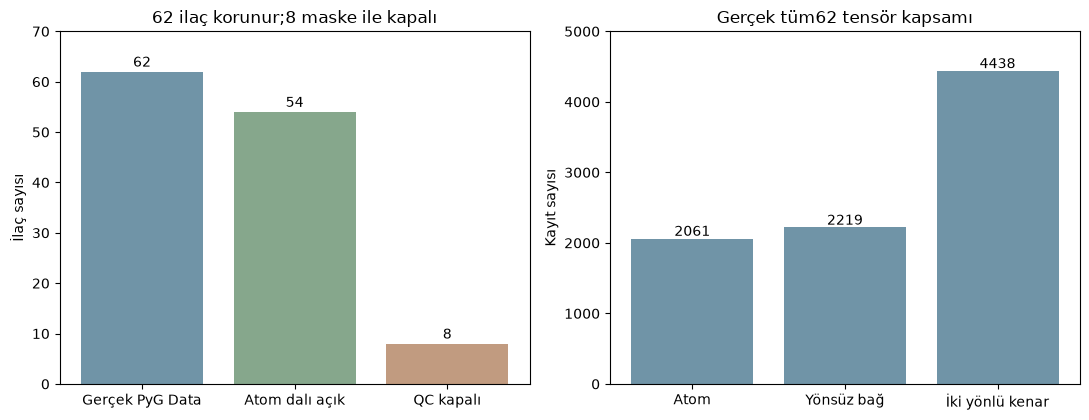

In [2]:
qa=pd.read_csv(QA/'molecular_graph_QA_all62.csv');display(qa)
display(qa[~qa.atom_eligible][['id','name','atoms','bonds','components','review_flags']])
fig,axs=plt.subplots(1,2,figsize=(11,4.3))
axs[0].bar(['Gerçek PyG Data','Atom dalı açık','QC kapalı'],[len(qa),qa.atom_eligible.sum(),(~qa.atom_eligible).sum()],color=['#7094a7','#86a78c','#c19b80'])
axs[0].set(ylabel='İlaç sayısı',title='62 ilaç korunur;8 maske ile kapalı',ylim=(0,70))
for i,v in enumerate([62,54,8]):axs[0].text(i,v+1,str(v),ha='center')
axs[1].bar(['Atom','Yönsüz bağ','İki yönlü kenar'],[qa.atoms.sum(),qa.bonds.sum(),qa.directed_edges.sum()],color='#7094a7')
axs[1].set(title='Gerçek tüm62 tensör kapsamı',ylabel='Kayıt sayısı')
for i,v in enumerate([qa.atoms.sum(),qa.bonds.sum(),qa.directed_edges.sum()]):axs[1].text(i,v+40,str(v),ha='center')
axs[1].set_ylim(0,5000)
plt.tight_layout();plt.savefig(F/'01_real_PyG_QC_scope.png',dpi=160);plt.show()

**Yorum:**2061 atom/2219 bağ4438 yönlü kenara açılır.54 atom maskesi mevcutQC kararıdır;8 ilaç veri kümesinden silinmez. Gentamicin105 atom/3 bağlantısız bileşen olarak tam korunur;en büyük fragment seçilmez. Methenamine atom dalı kapalı ve mevcut girdisiz abstention politikasında;Tobramycin protein eksiğiyle kimya+uygun atom dalında kalır. Teknik parse/graph uygunluğu biyolojik doğruluğun eksiksiz kanıtı değildir.

## 2.44 atom ve14 bağ özelliği neyi kodluyor?

,tür,alan,boyut,sabit_değerler
0,atom,element,10,"['C', 'N', 'O', 'F', 'P', 'S', 'Cl', 'Br', 'I', 'OTHER']"
1,atom,total_degree,8,"[0, 1, 2, 3, 4, 5, 6, 'OTHER']"
2,atom,formal_charge,6,"[-2, -1, 0, 1, 2, 'OTHER']"
3,atom,total_H,6,"[0, 1, 2, 3, 4, 'OTHER']"
4,atom,hybridization,6,"['SP', 'SP2', 'SP3', 'SP3D', 'SP3D2', 'OTHER']"
5,atom,aromatic,1,['bool']
6,atom,in_ring,1,['bool']
7,atom,CIP_state,5,"['R', 'S', 'UNASSIGNED_POTENTIAL', 'NONE', 'OTHER']"
8,atom,isotope_specified,1,['bool']
9,bond,bond_type,5,"['SINGLE', 'DOUBLE', 'TRIPLE', 'AROMATIC', 'OTHER']"


,id,atom_index,element,total_degree,formal_charge,total_H,hybridization,aromatic,in_ring,CIP_state,isotope_specified,raw_CIP,raw_chiral_tag,isotope,radical_electrons,implicit_H,explicit_H_count
784,DB00601,0,C,4,0,3,SP3,False,False,NONE,False,NaN,CHI_UNSPECIFIED,0,0,3,0
785,DB00601,1,C,3,0,0,SP2,False,False,NONE,False,NaN,CHI_UNSPECIFIED,0,0,0,0
786,DB00601,2,O,1,0,0,SP2,False,False,NONE,False,NaN,CHI_UNSPECIFIED,0,0,0,0
787,DB00601,3,N,3,0,1,SP2,False,False,NONE,False,NaN,CHI_UNSPECIFIED,0,0,1,0
788,DB00601,4,C,4,0,2,SP3,False,False,NONE,False,NaN,CHI_UNSPECIFIED,0,0,2,0
789,DB00601,5,C,4,0,1,SP3,False,True,S,False,S,CHI_TETRAHEDRAL_CW,0,0,0,1
790,DB00601,6,C,4,0,2,SP3,False,True,NONE,False,NaN,CHI_UNSPECIFIED,0,0,2,0
791,DB00601,7,N,3,0,0,SP2,False,True,NONE,False,NaN,CHI_UNSPECIFIED,0,0,0,0
792,DB00601,8,C,3,0,0,SP2,False,True,NONE,False,NaN,CHI_UNSPECIFIED,0,0,0,0
793,DB00601,9,O,1,0,0,SP2,False,False,NONE,False,NaN,CHI_UNSPECIFIED,0,0,0,0


,id,bond_index,begin_atom,end_atom,bond_type,stereo,conjugated,in_ring,raw_bond_stereo,potential_stereo_state,raw_bond_direction,stereo_atoms,forward_column,reverse_column
840,DB00601,0,0,1,SINGLE,STEREONONE,False,False,STEREONONE,NaN,NONE,[],0,1
841,DB00601,1,1,2,DOUBLE,STEREONONE,True,False,STEREONONE,NaN,NONE,[],2,3
842,DB00601,2,1,3,SINGLE,STEREONONE,True,False,STEREONONE,NaN,NONE,[],4,5
843,DB00601,3,3,4,SINGLE,STEREONONE,False,False,STEREONONE,NaN,NONE,[],6,7
844,DB00601,4,4,5,SINGLE,STEREONONE,False,False,STEREONONE,NaN,NONE,[],8,9
845,DB00601,5,5,6,SINGLE,STEREONONE,False,True,STEREONONE,NaN,NONE,[],10,11
846,DB00601,6,6,7,SINGLE,STEREONONE,False,True,STEREONONE,NaN,NONE,[],12,13
847,DB00601,7,7,8,SINGLE,STEREONONE,True,True,STEREONONE,NaN,NONE,[],14,15
848,DB00601,8,8,9,DOUBLE,STEREONONE,True,False,STEREONONE,NaN,NONE,[],16,17
849,DB00601,9,8,10,SINGLE,STEREONONE,True,True,STEREONONE,NaN,NONE,[],18,19


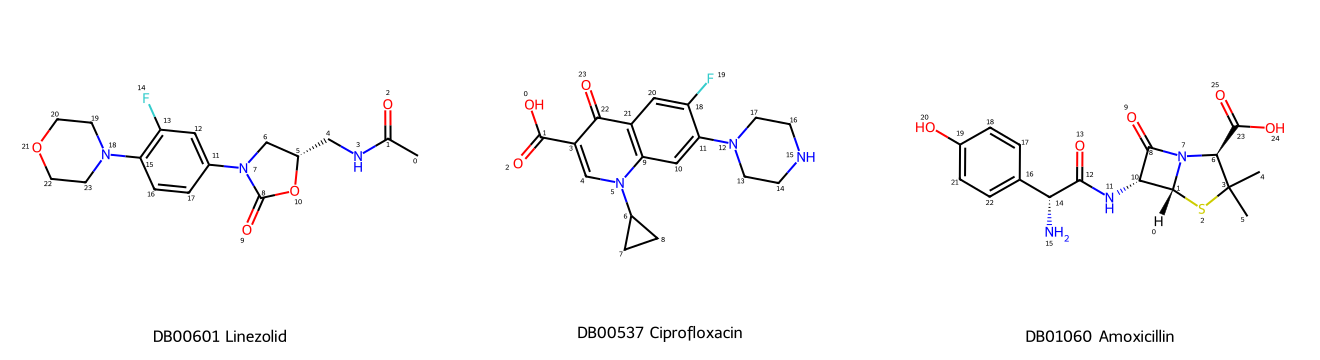

In [3]:
schema=json.loads((QA/'feature_schema.json').read_text(encoding='utf-8'));rows=[]
for kind,fields in schema['fields'].items():
    for field,values in fields.items():rows.append({'tür':kind,'alan':field,'boyut':len(values),'sabit_değerler':str(values)})
display(pd.DataFrame(rows))
atoms=pd.read_csv(QA/'atom_fields_all62.csv');bonds=pd.read_csv(QA/'bond_fields_all62.csv')
display(atoms[atoms.id.eq('DB00601')]);display(bonds[bonds.id.eq('DB00601')])
from rdkit.Chem import Draw
selected=['DB00601','DB00537','DB01060'];mols=[]
for d in selected:
    mol,status=parse_smiles(store.registry[d]['source_SMILES']);mols.append(mol)
options=Draw.MolDrawOptions();options.addAtomIndices=True
picture=Draw.MolsToGridImage(mols,molsPerRow=3,subImgSize=(440,360),legends=[d+' '+store.registry[d]['name'] for d in selected],drawOptions=options)
picture.save(F/'02_real_molecules_indexed.png');display(picture)

**Yorum:**Linezolid,Ciprofloxacin,Amoxicillin kaynak yapıları atom indeksleriyle gösterildi;2D koordinatlar girdi değildir. Formal yük,H sayısı,aromatiklik,bağ tipi veCIP ayrı alanlardır. R/S ile komşu sırasına bağlı ham@/@@ aynı şey değildir. Potansiyel fakat belirtilmemiş atom stereo UNASSIGNED_POTENTIAL;belirtilmemiş potansiyel çiftbağ STEREOANY olarak kodlanır,hamRDKit BondStereo metadatada aynen korunur. Bu sınıflama E/Z veya R/S tahmini değildir.

## 3. İki yönlü kenarlar ve bağ özellik hizası

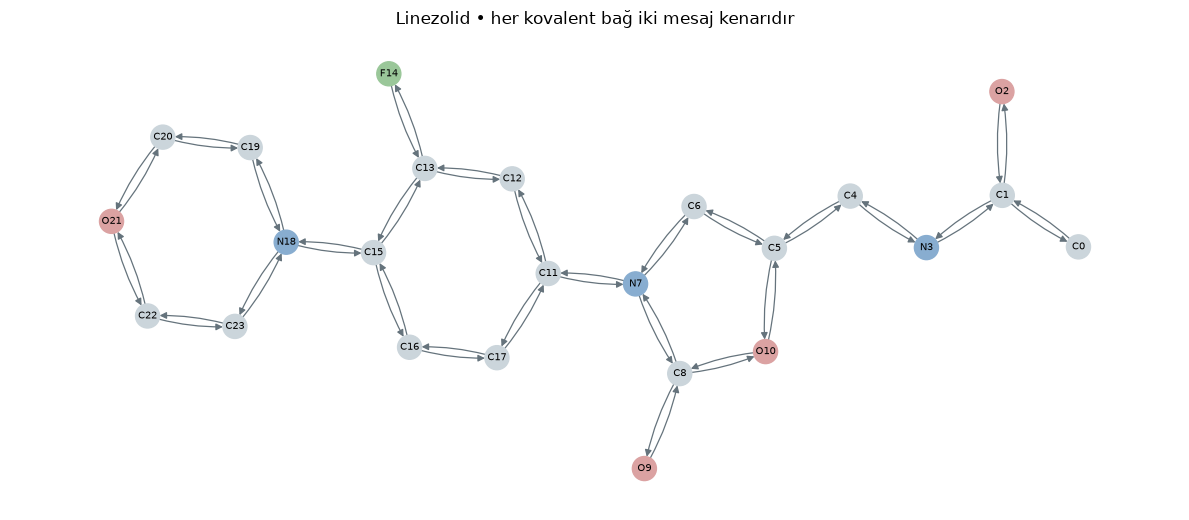

,RDKit_bond,ileri,ters,edge_attr_aynı,stereo,raw_direction
0,0,"[0, 1]","[1, 0]",True,STEREONONE,NONE
1,1,"[1, 2]","[2, 1]",True,STEREONONE,NONE
2,2,"[1, 3]","[3, 1]",True,STEREONONE,NONE
3,3,"[3, 4]","[4, 3]",True,STEREONONE,NONE
4,4,"[4, 5]","[5, 4]",True,STEREONONE,NONE
5,5,"[5, 6]","[6, 5]",True,STEREONONE,NONE
6,6,"[6, 7]","[7, 6]",True,STEREONONE,NONE


In [4]:
import networkx as nx
from rdkit.Chem import rdDepictor
d='DB00601';mol,_=parse_smiles(store.registry[d]['source_SMILES']);rdDepictor.Compute2DCoords(mol)
g=store.graphs[d];net=nx.DiGraph();net.add_nodes_from(range(g.num_nodes));net.add_edges_from(map(tuple,g.edge_index.T.tolist()))
pos={i:(mol.GetConformer().GetAtomPosition(i).x,mol.GetConformer().GetAtomPosition(i).y) for i in net}
colors={'C':'#cbd5db','N':'#88add0','O':'#dba2a2','F':'#9ac799'}
fig,ax=plt.subplots(figsize=(12,5.3))
nx.draw_networkx_nodes(net,pos,ax=ax,node_size=300,node_color=[colors.get(mol.GetAtomWithIdx(i).GetSymbol(),'#ddc28b') for i in net])
nx.draw_networkx_labels(net,pos,ax=ax,labels={i:mol.GetAtomWithIdx(i).GetSymbol()+str(i) for i in net},font_size=7)
nx.draw_networkx_edges(net,pos,ax=ax,arrows=True,arrowsize=10,node_size=300,connectionstyle='arc3,rad=0.09',edge_color='#65737c',width=.9)
ax.set_title('Linezolid • her kovalent bağ iki mesaj kenarıdır');ax.axis('off')
plt.tight_layout();plt.savefig(F/'03_Linezolid_two_direction_edges.png',dpi=160);plt.show()
alignment=[]
for b in store.registry[d]['raw_stereo_metadata']['bonds'][:7]:
    i,j=b['forward_column'],b['reverse_column'];alignment.append({'RDKit_bond':b['bond_index'],'ileri':str(g.edge_index[:,i].tolist()),'ters':str(g.edge_index[:,j].tolist()),'edge_attr_aynı':bool(torch.equal(g.edge_attr[i],g.edge_attr[j])),'stereo':b['stereo'],'raw_direction':b['raw_bond_direction']})
display(pd.DataFrame(alignment))

**Yorum:**Bu yönler kovalent bağın iki mesaj yönüdür;biyolojik nedensellik yönü değildir. İki yönde bağ-tipi ve E/Z gibi invariant özellikler aynıdır. Raw BondDir/stereo-atom referansları kaynakbegin/end indeksleriyle ayrımetadata'dadır;ters yöne körlemesine rawUP/DOWN özelliği kopyalanmaz. Çizgi türü burada bağ derecesini kodlamaz;bond-order bilgisi14boyutlu edge_attr tablosundadır.

## 4. Kontrollü sentetik forward ve türev

,kontrollü_kanıt
smiles,CCO
node_h0_first,"[1.0, 1.0, 2.0]"
node_h_first,"[3.25, 3.625, 4.75]"
graph_readout_first,3.875
expected_readout,3.875
d_output_d_atom_message_00,1.166667
expected_atom_gradient,1.166667
d_output_d_bond_message_single_00,1.0
expected_bond_gradient,1.0
optimizer_steps,0


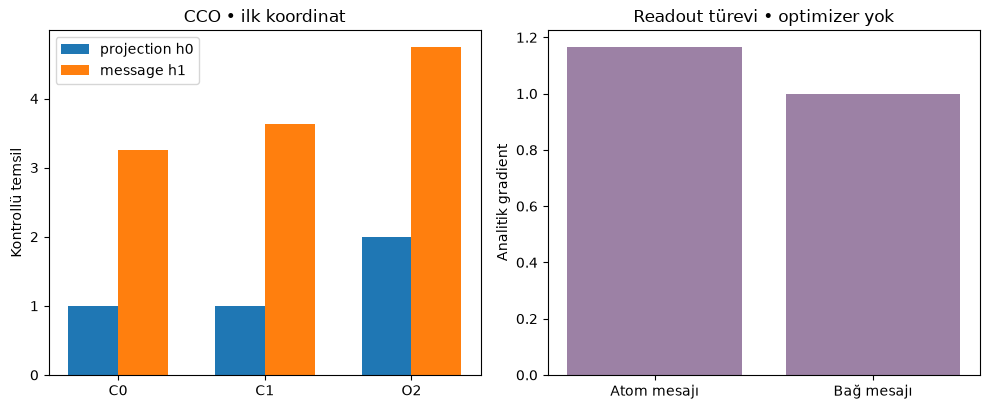

In [5]:
m=BondAwareMolecularEncoder().double()
with torch.no_grad():
    for p in m.parameters():p.zero_()
    m.projection.weight[0,0]=1;m.projection.weight[0,2]=2;m.self_update.weight[0,0]=.5
    m.atom_message.weight[0,0]=.75;m.bond_message.weight[0,0]=1;m.bond_message.weight[0,1]=3;m.readout.weight[0,0]=1
mol,_=parse_smiles('CCO');data,raw=build_graph(mol);out=m(Batch.from_data_list([data]));out['molecular_h'].sum().backward()
proof=json.loads((QA/'synthetic_analytic_proof.json').read_text(encoding='utf-8'))
display(pd.DataFrame([proof]).T.rename(columns={0:'kontrollü_kanıt'}))
assert abs(out['molecular_h'][0,0].item()-3.875)<1e-12
assert abs(m.atom_message.weight.grad[0,0].item()-7/6)<1e-12
fig,axs=plt.subplots(1,2,figsize=(10,4.2));i=np.arange(3)
axs[0].bar(i-.17,proof['node_h0_first'],width=.34,label='projection h0');axs[0].bar(i+.17,proof['node_h_first'],width=.34,label='message h1')
axs[0].set_xticks(i,['C0','C1','O2']);axs[0].set(title='CCO • ilk koordinat',ylabel='Kontrollü temsil');axs[0].legend()
axs[1].bar(['Atom mesajı','Bağ mesajı'],[proof['d_output_d_atom_message_00'],proof['d_output_d_bond_message_single_00']],color='#9c81a5');axs[1].set(title='Readout türevi • optimizer yok',ylabel='Analitik gradient')
plt.tight_layout();plt.savefig(F/'04_synthetic_forward_gradient.png',dpi=160);plt.show()

**Yorum:** Tek adımda h0=[1,1,2],h1=[3,25;3,625;4,75] ve mean readout3,875 çıkar. Atom-message türevi7/6,bağ-message türevi1'dir. Bağ kaldırma ve bond-type değişimi testlerde beklenen3,1667 ve4,875 readout'larına gider. Bu elle belirlenmiş ayırt edici kanıt ağırlıklarıdır;optimizer veya yan etki kaybı yoktur.

## 5. Gerçek moleküllerde forward ve gradient

,id,name,edge_removed_output_L2,bond_type_perturbed_output_L2,atom_message_gradient_norm,bond_message_gradient_norm,optimizer_steps,weights_unchanged,perturbation_semantics
0,DB00601,Linezolid,0.004479,0.007499,0.306958,0.828682,0,True,feature-level software probe; NOT a validated alternative chemical structure
1,DB00537,Ciprofloxacin,0.003461,0.003940,0.349219,0.991111,0,True,feature-level software probe; NOT a validated alternative chemical structure
2,DB01060,Amoxicillin,0.004395,0.004894,0.412755,1.008703,0,True,feature-level software probe; NOT a validated alternative chemical structure


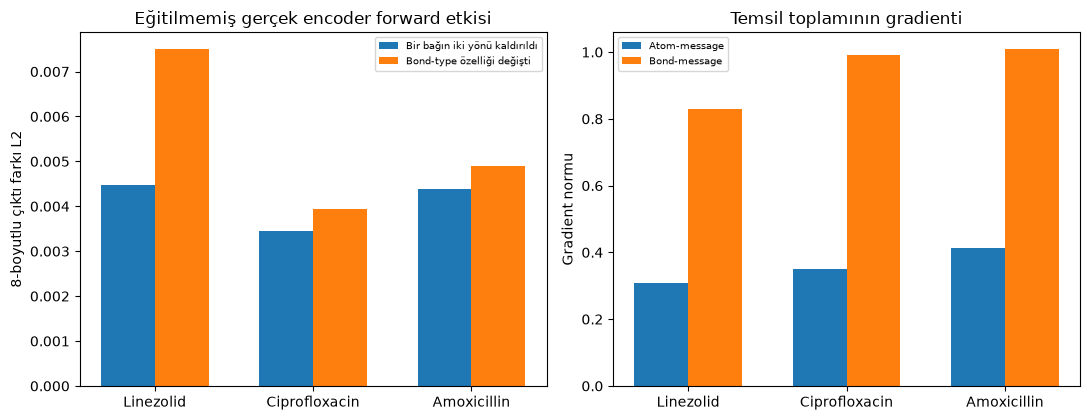

In [6]:
real=pd.read_csv(QA/'real_molecular_forward_gradient.csv');display(real)
fig,axs=plt.subplots(1,2,figsize=(11,4.3));i=np.arange(len(real))
axs[0].bar(i-.17,real.edge_removed_output_L2,width=.34,label='Bir bağın iki yönü kaldırıldı');axs[0].bar(i+.17,real.bond_type_perturbed_output_L2,width=.34,label='Bond-type özelliği değişti')
axs[1].bar(i-.17,real.atom_message_gradient_norm,width=.34,label='Atom-message');axs[1].bar(i+.17,real.bond_message_gradient_norm,width=.34,label='Bond-message')
for ax in axs:ax.set_xticks(i,real.name);ax.legend(fontsize=7)
axs[0].set(title='Eğitilmemiş gerçek encoder forward etkisi',ylabel='8-boyutlu çıktı farkı L2');axs[1].set(title='Temsil toplamının gradienti',ylabel='Gradient normu')
plt.tight_layout();plt.savefig(F/'05_real_forward_gradient.png',dpi=160);plt.show()

**Yorum:**Linezolid,Ciprofloxacin,Amoxicillin'de atom ve bağ message parametrelerine gradient ulaştı;kenar veya bond-type özelliği değişince çıktı değişti. Perturbasyonlar yazılım duyarlılık probe'udur;kimyasal olarak geçerli yeni molekül/ilaç,mekanizma veya yan etki açıklaması değildir. Ağırlıklar değişmedi,optimizer adımı0.

## 6. Permütasyon,başlangıç hash'i ve kapasite

In [7]:
permutation=pd.read_csv(QA/'permutation_all62.csv');display(permutation)
display(pd.read_csv(QA/'actual_parameter_counts.csv'))
display(pd.DataFrame([json.loads((QA/'UNTRAINED_initial_state.json').read_text(encoding='utf-8'))]).T)
model=initialized_model();model_again=initialized_model()
from wp10_molecular_encoder import model_digest
assert model_digest(model)==model_digest(model_again)
with torch.no_grad():sample=model.molecular(store.make_batch(['DB00601','DB00537','DB01060']).batch)
display(pd.DataFrame([{'tensör':key,'boyut':str(tuple(value.shape))} for key,value in sample.items()]))

,id,max_absolute_readout_error,pass_atol_1e_12,permutation_sha256
0,DB00199,1.110223e-16,True,eb4d8168f586e581c8eed0d7dd681bc7db94f14743eb956f641d93c81d23af69
1,DB00207,1.110223e-16,True,3ec7768b8d46ab8ddcaca5c0931f2c6f23b25fb60d13bb850ca15b98b1bac0b4
2,DB00254,2.775558e-17,True,07f1423b175a05b2c6e689035ad8d4eebd2d77eda53a19e304419937417b5190
3,DB00259,1.387779e-17,True,f6402d7774ac3e5e2772bb9ccb302b5d711a7ec0008f01d4c47f25551daa36fd
4,DB00301,5.551115e-17,True,a5c6193fae57dc4850d4e6d6ca38aa78f519ede73b0f7cbc776e71d2a19b298e
5,DB00303,3.816392e-17,True,810d9d87e3b91c1f05a1a3c59bcb811288f6e1a2cb0bbbbfd6d7412e0ca3496b
6,DB00319,5.551115e-17,True,e1b6bc434a38717f1c3ffd385c6bc80c5784faa34b5d454029441198a08677b9
7,DB00359,1.387779e-17,True,9477fabaff25d69a24ebc91e46e82802aa9a4117987d09f1857384063e844f00
8,DB00415,5.551115e-17,True,9cbb3c5e92c15a06bac6f9c2e63145557445c03781df2fefcf1fed142a22786e
9,DB00417,5.551115e-17,True,a5f3f52c7af28b0cedaa18e1083009fc55c455d17b3a054a458055c169eb2bcb


,K_synthetic_shape_only,actual_parameters,expected_parameters,head_used_on_real_data
0,0,5512,5512,False
1,3,5965,5965,False
2,158,29370,29370,False
3,326,54738,54738,False


,0
version,WP10-molecular-encoder-v1
seed,20261106
state_sha256,a78ade023c3315ada0b7bf69bb70ad2894387aae7d2ac23155089a16dd490684
parameters,5512
molecular_parameters,1592
trained,False
PT_head,False
optimizer_steps,0
purpose,initialization reproducibility only; NOT a fitted ADR model


,tensör,boyut
0,molecular_h,"(3, 8)"
1,node_h,"(74, 16)"
2,node_h0,"(74, 16)"
3,neighbor_mean,"(74, 16)"


**Yorum:**62 gerçek yapının atomları yeniden sıralanıp stereo özellikleri yeniden çıkarıldı. Float64 readout farkı en fazla2,08×10⁻¹⁶,önceden belirlenen tolerans1e-12 altında. Atom indeksi öğrenme özelliği değildir. Dal1592;protein/kimya+atom5512 parametre. Opsiyonel sentetikK başlığı5512+151K olarak sayıldı;gerçek veri forward'unda headNone. NPZ snapshot **UNTRAINED** başlangıç içindir,yan etki modeli değildir. NPZ zip baytları yerine dtype/shape/tensor bayt hash'i sayısal tekrar üretimi tanımlar.

## 7.141→150 füzyon ve dört anahtar

,context,variant,seed,initial_state_sha256,train_drugs,query_drugs,train_dim,query_dim,base_dim,molecular_dim,train_active_atom_mask,query_active_atom_mask,train_PPI_neighbor_input_norm,train_cache_unchanged,model_state_unchanged,PT_head,optimizer_steps
0,primary_o01_final,A0P0,20261206,957cceced85fe5b241e2aa5cfcd76f54b03ebb2fd9ac7697b9a0e37d3e29fea6,49,13,150,150,141,8,0,0,0.000000,True,True,False,0
1,primary_o01_final,A0P1,20261206,957cceced85fe5b241e2aa5cfcd76f54b03ebb2fd9ac7697b9a0e37d3e29fea6,49,13,150,150,141,8,0,0,10.261417,True,True,False,0
2,primary_o01_final,A1P0,20261206,957cceced85fe5b241e2aa5cfcd76f54b03ebb2fd9ac7697b9a0e37d3e29fea6,49,13,150,150,141,8,43,11,0.000000,True,True,False,0
3,primary_o01_final,A1P1,20261206,957cceced85fe5b241e2aa5cfcd76f54b03ebb2fd9ac7697b9a0e37d3e29fea6,49,13,150,150,141,8,43,11,10.261417,True,True,False,0
4,primary_o01_i01,A0P0,20261207,88954b469a21a489ce6f2bdebd1ceeac8805d865fef49228527eebac986b898a,32,30,150,150,141,8,0,0,0.000000,True,True,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
155,stress_o05_i02,A1P1,20271608,361bb82f02a6dc1986ea0d20c4014a7e4f36f16e3866e32776b80aa206f8191c,33,29,150,150,141,8,28,26,10.220998,True,True,False,0
156,stress_o05_i03,A0P0,20271609,ddea4e4374b8eef4b5dcc3427befc26cea48497e468872866f39efb4ec5c7421,34,28,150,150,141,8,0,0,0.000000,True,True,False,0
157,stress_o05_i03,A0P1,20271609,ddea4e4374b8eef4b5dcc3427befc26cea48497e468872866f39efb4ec5c7421,34,28,150,150,141,8,0,0,10.398482,True,True,False,0
158,stress_o05_i03,A1P0,20271609,ddea4e4374b8eef4b5dcc3427befc26cea48497e468872866f39efb4ec5c7421,34,28,150,150,141,8,28,26,0.000000,True,True,False,0


,context,seed,initial_state_sha256,train_drugs,query_drugs,train_dim,query_dim,base_dim,molecular_dim,train_active_atom_mask,query_active_atom_mask,train_PPI_neighbor_input_norm,train_cache_unchanged,model_state_unchanged,PT_head,optimizer_steps
variant,,,,,,,,,,,,,,,,
A0P0,primary_o01_final,20261206,957cceced85fe5b241e2aa5cfcd76f54b03ebb2fd9ac7697b9a0e37d3e29fea6,49,13,150,150,141,8,0,0,0.000000,True,True,False,0
A0P1,primary_o01_final,20261206,957cceced85fe5b241e2aa5cfcd76f54b03ebb2fd9ac7697b9a0e37d3e29fea6,49,13,150,150,141,8,0,0,10.261417,True,True,False,0
A1P0,primary_o01_final,20261206,957cceced85fe5b241e2aa5cfcd76f54b03ebb2fd9ac7697b9a0e37d3e29fea6,49,13,150,150,141,8,43,11,0.000000,True,True,False,0
A1P1,primary_o01_final,20261206,957cceced85fe5b241e2aa5cfcd76f54b03ebb2fd9ac7697b9a0e37d3e29fea6,49,13,150,150,141,8,43,11,10.261417,True,True,False,0


,train_repr,query_repr,gerçek_PT_head,train_query_ID_ortak
0,"(49, 150)","(13, 150)",None,0


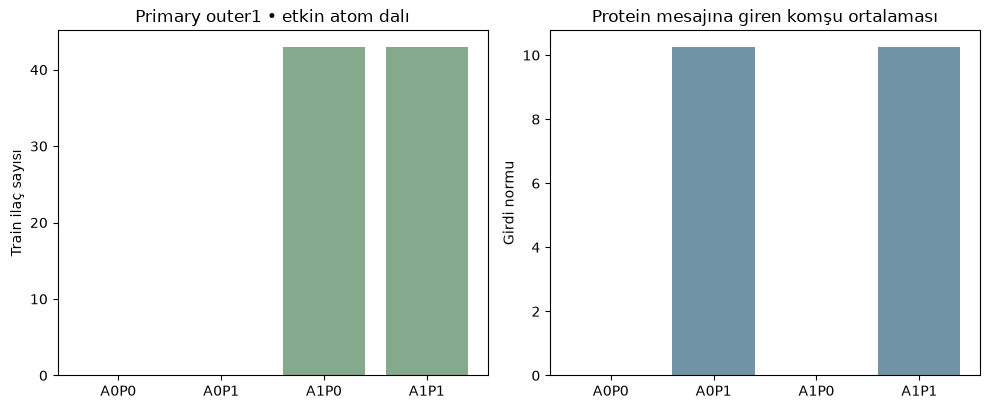

In [8]:
checks=pd.read_csv(QA/'integration_forward_40contexts_4variants.csv');display(checks)
first=checks[checks.context.eq('primary_o01_final')].set_index('variant').loc[list(VARIANTS)];display(first)
g,q,tm,qm=load_context('primary_o01_final',store)
model=initialized_model()
with torch.no_grad():
    train=model.encode_train(g,tm,'A1P1');query=model.encode_query(g,q,qm,train['cache'])
display(pd.DataFrame([{'train_repr':str(tuple(train['representation'].shape)),'query_repr':str(tuple(query['representation'].shape)),'gerçek_PT_head':model.head,'train_query_ID_ortak':len(set(tm.ids)&set(qm.ids))}]))
fig,axs=plt.subplots(1,2,figsize=(10,4.2))
axs[0].bar(first.index,first.train_active_atom_mask,color='#85a98d');axs[0].set(title='Primary outer1 • etkin atom dalı',ylabel='Train ilaç sayısı')
axs[1].bar(first.index,first.train_PPI_neighbor_input_norm,color='#7093a5');axs[1].set(title='Protein mesajına giren komşu ortalaması',ylabel='Girdi normu')
plt.tight_layout();plt.savefig(F/'06_four_variant_switches.png',dpi=160);plt.show()

**Yorum:**40 frozen bağlam×4 anahtar160 teknik train/query forward geçti. A0'da molekül8+maske1 bloğu tam0;P0'da protein komşu ortalaması0. Aynı contextte dört anahtar aynı başlangıç/parametre/ID kapsamını taşır. Atom dalı kapalıyken de150 boyut korunur;bu frozenWP09 modelini değiştirmez. Protein cache'inin state/graph bağı doğrulanır;query başkaquery'yi veyacache'i değiştirmez.

Bu40 bağlam teknik şekil/izolasyon denetimidir;WP09 null nedeniyle seçimden çıkarılmış iki inner bağlamı gelecek eğitim planına geri almak değildir. Gelecekteki gerçek trainer ayrıca train-only PT loss/seçim testleri gerektirir;encoder testi henüz yazılmamış trainer'ın doğruluğunu kanıtlamaz.

## 8. Testler ve eğitim kapısı

In [9]:
text=(QA/'test_results_context_guard.txt').read_text(encoding='utf-8-sig');test=re.search(r'Ran ([0-9]+) tests in ([0-9.]+)s',text)
display(pd.DataFrame([{'gerçek_test':int(test.group(1)),'saniye':float(test.group(2)),'durum':'PASS' if text.rstrip().endswith('OK') else 'FAIL','optimizer':0,'PT_skoru':False}]))
display(pd.read_csv(QA/'train_query_scope_manifest.csv').head(4))
display(pd.DataFrame([{'alan':'Gerçek dört kollu eğitim','durum':'AYRI KULLANICI ONAYI BEKLİYOR'},
    {'alan':'Outer PT skorlaması / performans','durum':'YAPILMADI'}, {'alan':'R0/R1/R2 ek moleküler ablation','durum':'Gelecek deney kapsamı kararı;ağ/model araması yok'}]))

,gerçek_test,saniye,durum,optimizer,PT_skoru
0,28,10.556,PASS,0,False


,context,train_drug_ids,query_drug_ids,train_atom_mask,query_atom_mask,train_bundle_numeric_sha256,query_bundle_numeric_sha256,PT_labels_read
0,primary_o01_final,"[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""DB00303"", ""DB00319"", ""DB00359"", ""DB00415...","[""DB00254"", ""DB00438"", ""DB00446"", ""DB00479"", ""DB00493"", ""DB00537"", ""DB00685"", ""DB01137...","[true, true, true, true, true, true, true, true, true, true, true, true, true, true, t...","[true, true, true, true, true, true, true, true, false, false, true, true, true]",2db970af50c4d75e8fe5af6b316da1be2fe5ba103fbda7c262487850a26a1607,9ff94fc3228d7a3221b41b5b95b40ca177cccf8fa94ba09dcc41ecb57045f55b,False
1,primary_o01_i01,"[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""DB00303"", ""DB00319"", ""DB00359"", ""DB00415...","[""DB00254"", ""DB00417"", ""DB00438"", ""DB00446"", ""DB00479"", ""DB00493"", ""DB00535"", ""DB00537...","[true, true, true, true, true, true, true, true, true, true, true, true, true, false, ...","[true, true, true, true, true, true, true, true, true, true, true, true, false, true, ...",063f9065bb621fdefb97b84c2b157c5914ed9c774af1580ecf3dae981ccf8c22,7dc2c502a6494f928a580f4d12bc7080c6bc4796341fe57d43c1e7449a7f89b4,False
2,primary_o01_i02,"[""DB00199"", ""DB00207"", ""DB00303"", ""DB00359"", ""DB00417"", ""DB00485"", ""DB00535"", ""DB00560...","[""DB00254"", ""DB00259"", ""DB00301"", ""DB00319"", ""DB00415"", ""DB00438"", ""DB00440"", ""DB00446...","[true, true, true, true, true, true, true, true, true, true, true, true, true, false, ...","[true, true, true, true, true, true, true, true, true, true, true, true, false, true, ...",70b4225d1b44671fcdd35b33d2a2398c39447d13425e537f1af36f757a9e8fd2,849b33acf7c77c9be2d6f9c2952a41e0447022efb9e432431c66638e70e1a052,False
3,primary_o01_i03,"[""DB00259"", ""DB00301"", ""DB00319"", ""DB00415"", ""DB00417"", ""DB00440"", ""DB00512"", ""DB00535...","[""DB00199"", ""DB00207"", ""DB00254"", ""DB00303"", ""DB00359"", ""DB00438"", ""DB00446"", ""DB00479...","[true, true, true, true, true, true, true, true, false, true, true, true, true, true, ...","[true, true, true, true, true, true, true, true, true, true, true, true, true, true, t...",7f0bebb9307f50d327c5f8f2438a10c7626f4e9dd976cc24cfcf46a6f2abf969,e7cebff19d3ad2ff12763dc2e4fbfc0c5fa821bce723fac11a98a0303f63681b,False


,alan,durum
0,Gerçek dört kollu eğitim,AYRI KULLANICI ONAYI BEKLİYOR
1,Outer PT skorlaması / performans,YAPILMADI
2,R0/R1/R2 ek moleküler ablation,Gelecek deney kapsamı kararı;ağ/model araması yok


**Yorum:**28 test sentetik kimya,gerçek62 Data,54/8 maskesi,feature boyut/semantik/direction,permutation,edge/gradient,iki dal kapatma,query/cache izolasyonu,heldout/PT enjeksiyon reddi,tüm40 frozen üyelik,seed/tensor hash veparametre sayısını doğruladı. WP09/B0/B1/B2 sonuçları veQC kaynakları değişmedi;önceki2384 artefaktın hash'i korundu.

Atom-GNN ve protein-PPI artık teknik olarak birleştirilebilir;gerçek yan etki öğrenimi veya performans katkısı henüz ölçülmedi. Bu yüzden tam moleküler GiG araştırması tamamlandı denmez. SIDER unknown gerçek biyolojik negatif değildir;gelecekteki skorlar klinik risk olasılığı değildir. **WP10 encoder teknik doğrulamasında durulur;gerçek dört kollu eğitim için kullanıcı onayı beklenir.**